# NOAA OLR event-implied equivalent depths: 2σ envelopes

**Question:** What depths are implied by the stronger NOAA wave events, and how
do event counts and event-footprint energies vary with wave family?

The 1990–2010 record uses the completed **2σ longitudinal Hilbert-envelope
catalogs**, with all five wave families and the existing raw component-supported
sinusoid fits. The previous 1.5σ notebook is preserved in Git and the data backup.
This remake focuses on the observed events; Gaussian comparisons are deferred.

## Inputs and choices

NOAA daily OLR uses its 1-degree grid, with symmetry projection over 20°S–20°N
and northern 0–20° averaging as in the event catalogs.

The audited inputs come from `data/event_threshold_comparison/distributions_sigma2/`.
Active pixels have envelope amplitude greater than twice the signed filtered
OLR standard deviation, measured excluding 150 days at each record end.
The cutoff is relative to each wave's variance. Detection is unchanged between
the two fit selections below.

**Screened** uses `keep_for_histogram`: successful, dispersion-valid fits away
from search-grid edges, R² ≥ 0.3, at least half a spatial cycle and one temporal
cycle. **Relaxed** keeps all successful, positive, dispersion-valid depths.
Every selected event remains in its distribution's denominator, including depths
outside the displayed range. Linear bins are 1 m wide; log bins span 0.5–10,000 m.
Counts give equal weight to events and do not measure their strength.

In [1]:
import json
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from src.paths import DATA_DIR

DETECTION_SIGMA = 2.0
INPUT = DATA_DIR / "event_threshold_comparison/distributions_sigma2"
WAVES = ("Kelvin", "n1ERW", "MRG", "n0EIG", "n1WIG")
LABELS = {"Kelvin": "Kelvin", "n1ERW": "n=1 ER", "MRG": "MRG", "n0EIG": "n=0 EIG", "n1WIG": "n=1 WIG"}
COLORS = dict(zip(WAVES, ["C0", "C1", "C2", "C3", "C4"]))
SELECTIONS = {"screened": "Quality-screened", "relaxed": "All valid-depth fits"}
STYLES = {"screened": "-", "relaxed": "--"}
EDGES_M = np.arange(1.0, 201.0)
LOG_EDGES_M = np.geomspace(0.5, 10_000, 51)
COUNT_BINS = [f"count_{i:03d}m" for i in range(1, 200)]
LOG_BINS = [f"log_count_{i:02d}" for i in range(50)]
audit = json.loads((INPUT / "audit.json").read_text())
assert audit["status"] == "complete" and audit["detection_sigma"] == DETECTION_SIGMA
counts = pd.read_csv(INPUT / "noaa_event_counts.csv.gz")
energy = pd.read_csv(INPUT / "noaa_event_energy.csv.gz")
spectral = pd.read_csv(INPUT / "noaa_spectral_power.csv.gz")
summary = pd.read_csv(DATA_DIR / "event_threshold_comparison/catalog_summary.csv")
summary = summary.loc[summary.model.eq("NOAA_OLR") & summary.detection_sigma.eq(DETECTION_SIGMA)]
for frame in (counts, energy):
    assert len(frame) == 10 and frame.detection_sigma.eq(DETECTION_SIGMA).all()
    assert set(frame.wave_type) == set(WAVES) and frame.selected_events.gt(0).all()
assert len(spectral) == 5 and spectral.source.eq("observed").all()
assert len(summary) == 5


## All wave families in one panel

This overview overlays all five **2σ** wave populations. The selection is
explicit in the next cell; change it to `"relaxed"` for all valid-depth fits.
Each wave is normalized separately, so a more common wave does not dominate
merely by contributing more events. Depths outside 1–100 m remain in the denominator.

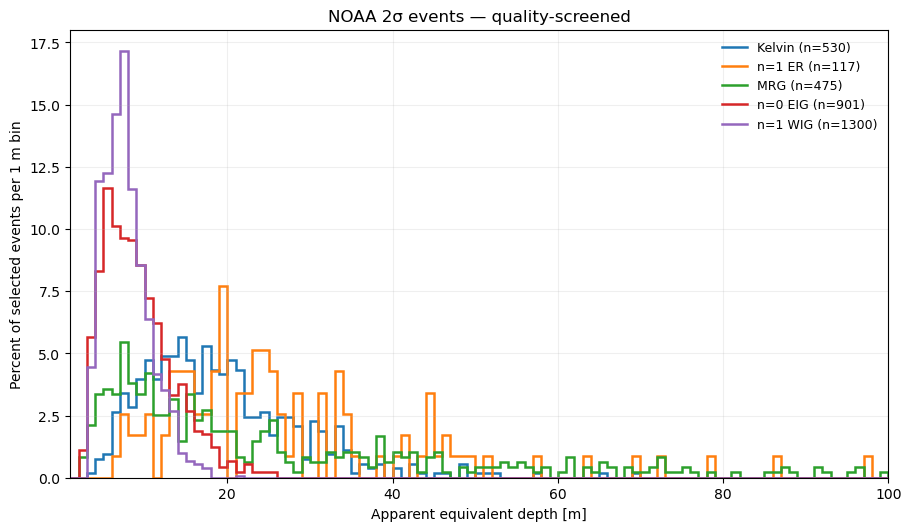

In [2]:
OVERVIEW_SELECTION = "screened"
OVERVIEW_EDGES_M = np.arange(1.0, 101.0)
OVERVIEW_BINS = [f"count_{i:03d}m" for i in range(1, 100)]
fig, ax = plt.subplots(figsize=(9, 5.2), layout="constrained")
for wave in WAVES:
    row = counts.loc[counts.wave_type.eq(wave) & counts.selection.eq(OVERVIEW_SELECTION)].iloc[0]
    percent = 100 * row[OVERVIEW_BINS].to_numpy(dtype=float) / row.selected_events
    ax.stairs(percent, OVERVIEW_EDGES_M, color=COLORS[wave], linewidth=1.8,
              label=f"{LABELS[wave]} (n={int(row.selected_events)})")
ax.set(xlim=(1, 100), ylim=(0, None), xlabel="Apparent equivalent depth [m]",
       ylabel="Percent of selected events per 1 m bin",
       title=f"NOAA 2σ events — {SELECTIONS[OVERVIEW_SELECTION].lower()}")
ax.legend(frameon=False, fontsize=9)
ax.grid(alpha=.2)
plt.show()


## Counts, depth medians and out-of-range tails

The same detections supply both fit selections. MRG can have very large
branch-inverted depths, so the omitted tails are reported explicitly.

In [3]:
columns = ["wave", "candidates", "valid_depths", "screened_events", "median_fit_r2",
           "median_spatial_cycles", "median_temporal_cycles", "valid_h_median_m", "screened_h_median_m"]
display(summary[columns].set_index("wave").reindex(WAVES).round(3))
tails = counts[["wave_type", "selection", "selected_events"]].copy()
for column in ("below_1m", "above_200m", "below_0p5m", "above_10000m"):
    tails[column + "_pct"] = 100 * counts[column] / counts.selected_events
display(tails.round(3))


,candidates,valid_depths,screened_events,median_fit_r2,median_spatial_cycles,median_temporal_cycles,valid_h_median_m,screened_h_median_m
wave,,,,,,,,
Kelvin,2573,2573,530,0.984,0.570,0.517,14.820,17.531
n1ERW,887,887,117,0.984,0.501,0.500,19.980,23.162
MRG,2389,2289,475,0.990,0.506,0.503,54.038,18.989
n0EIG,2989,2989,901,0.990,0.478,0.814,8.791,8.270
n1WIG,3045,3045,1300,0.992,0.529,1.020,7.865,7.330


,wave_type,selection,selected_events,below_1m_pct,above_200m_pct,below_0p5m_pct,above_10000m_pct
0,Kelvin,screened,530,0.000,0.000,0.0,0.000
1,Kelvin,relaxed,2573,0.000,0.000,0.0,0.000
2,MRG,screened,475,0.000,4.000,0.0,0.211
3,MRG,relaxed,2289,0.568,23.285,0.0,1.442
4,n0EIG,screened,901,0.000,0.000,0.0,0.000
5,n0EIG,relaxed,2989,0.000,0.000,0.0,0.000
6,n1ERW,screened,117,0.000,0.000,0.0,0.000
7,n1ERW,relaxed,887,0.000,0.000,0.0,0.000
8,n1WIG,screened,1300,0.000,0.000,0.0,0.000
9,n1WIG,relaxed,3045,0.000,0.000,0.0,0.000


## Logarithmic depth distributions

Each panel shows the same wave's two fit selections. Densities are fractions
per decade of depth; neither curve is a background distribution or confidence band.

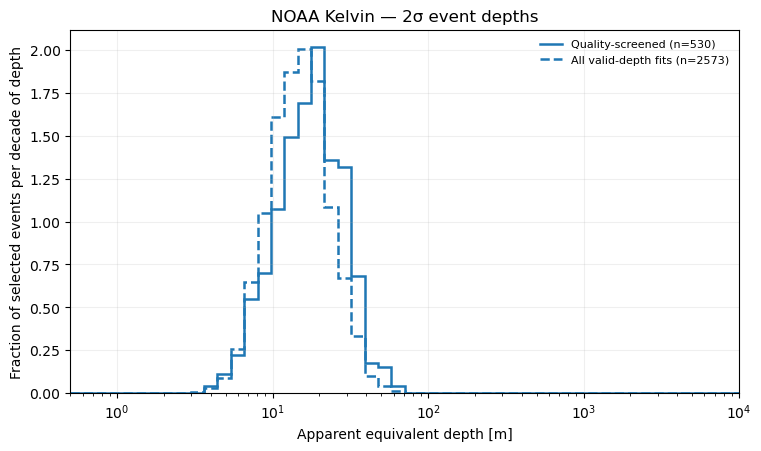

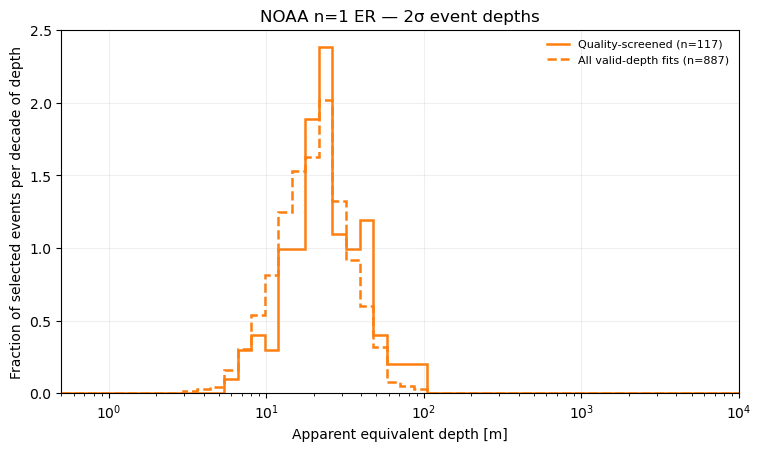

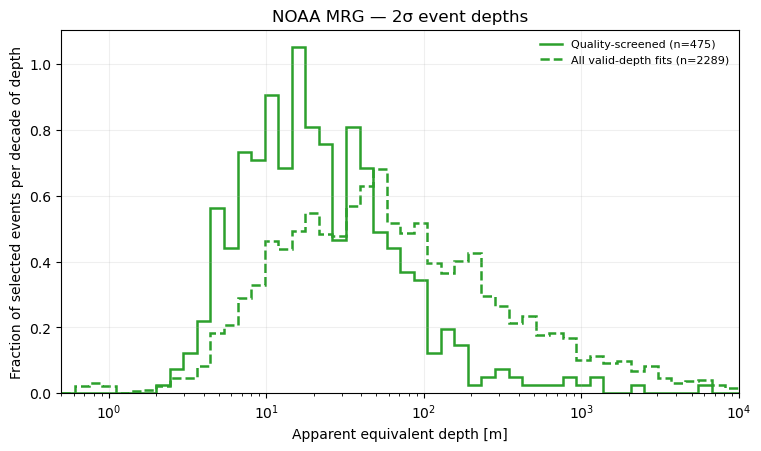

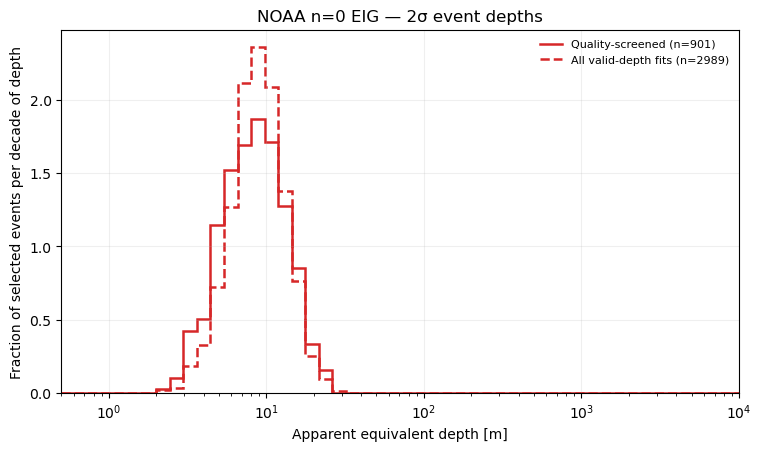

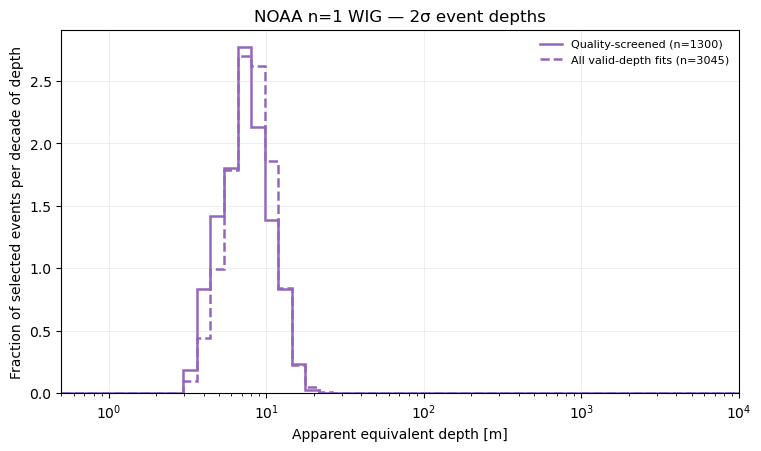

In [4]:
log_widths = np.diff(np.log10(LOG_EDGES_M))
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.4), layout="constrained")
    for selection, label in SELECTIONS.items():
        row = counts.loc[counts.wave_type.eq(wave) & counts.selection.eq(selection)].iloc[0]
        density = row[LOG_BINS].to_numpy(dtype=float) / row.selected_events / log_widths
        ax.stairs(density, LOG_EDGES_M, baseline=None, linestyle=STYLES[selection],
                  color=COLORS[wave], linewidth=1.8, label=f"{label} (n={int(row.selected_events)})")
    ax.set(xscale="log", xlim=(.5, 10_000), ylim=(0, None),
           xlabel="Apparent equivalent depth [m]", ylabel="Fraction of selected events per decade of depth",
           title=f"NOAA {LABELS[wave]} — 2σ event depths")
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=.2)
    plt.show()


## Linear detail, 1–200 m

Both selections retain all selected events in the denominator. The first bin
covers 1–2 m; it does not imply a resolved mode at exactly 1 m.

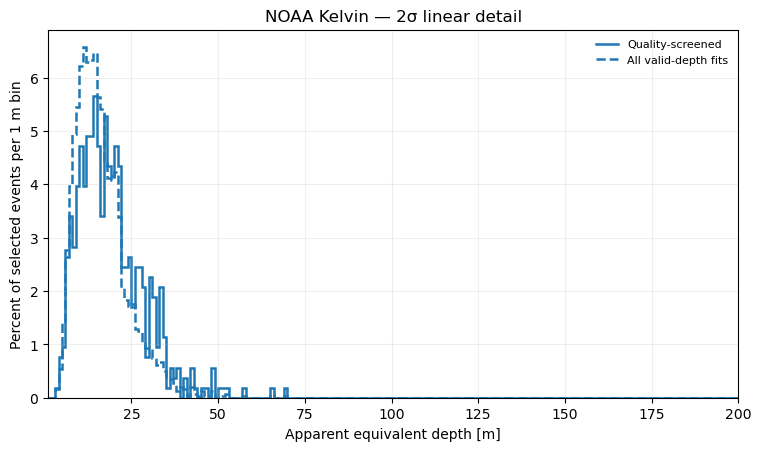

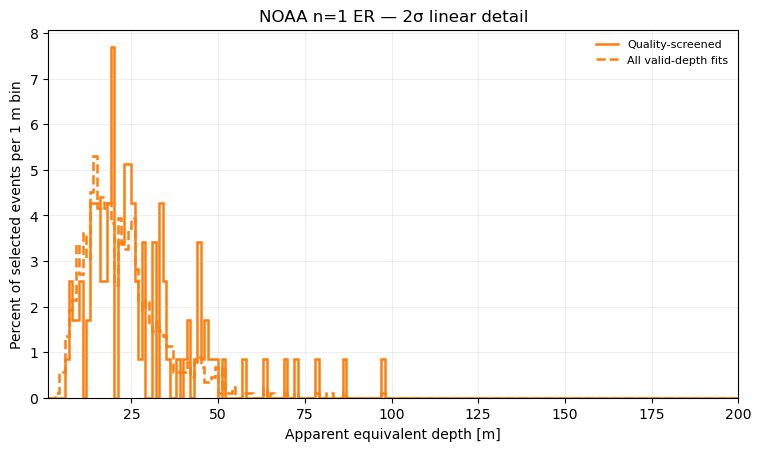

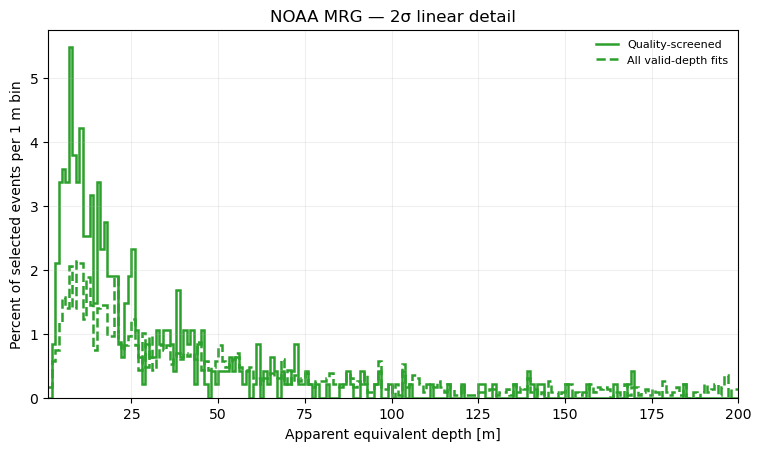

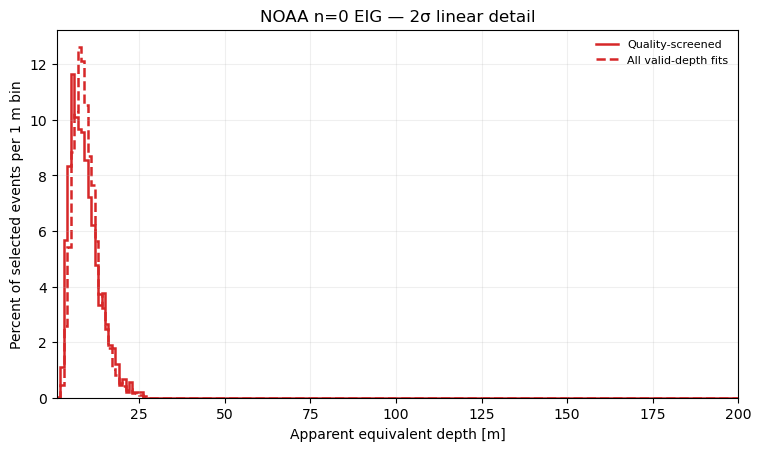

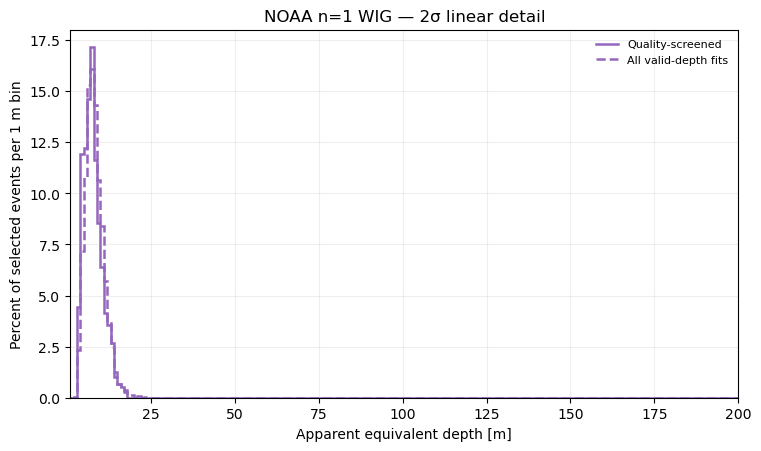

In [5]:
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.4), layout="constrained")
    for selection, label in SELECTIONS.items():
        row = counts.loc[counts.wave_type.eq(wave) & counts.selection.eq(selection)].iloc[0]
        percent = 100 * row[COUNT_BINS].to_numpy(dtype=float) / row.selected_events
        ax.stairs(percent, EDGES_M, baseline=None, color=COLORS[wave],
                  linestyle=STYLES[selection], linewidth=1.8, label=label)
    ax.set(xlim=(1, 200), ylim=(0, None), xlabel="Apparent equivalent depth [m]",
           ylabel="Percent of selected events per 1 m bin", title=f"NOAA {LABELS[wave]} — 2σ linear detail")
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=.2)
    plt.show()


## Energy on detected event footprints

For each new 2σ component, filtered OLR squared is summed over its active pixels.
The denominator is total preprocessed, projected OLR energy before wave filtering.
These panels retain both event prevalence and amplitude differences. They show
all filtered signal on the pixels, rather than excess over a background.

For event $e$ with support $S_e$, the footprint quantity is
$E_e=\sum_{S_e}(q_w-\overline q_w)^2$. The table reports all selected depths,
the displayed 1–200 m subset and the descriptive 12–50 m interval, as percentages
of total projected OLR energy.

,wave_type,selection,selected_events,support_all_depths_pct,support_1_to_200_pct,support_12_to_50_pct,fitted_all_depths_pct,fitted_1_to_200_pct,fitted_12_to_50_pct
0,Kelvin,screened,530,2.811,2.811,2.172,2.178,2.178,1.660
1,Kelvin,relaxed,2573,4.403,4.403,3.197,3.366,3.366,2.410
2,MRG,screened,475,1.139,1.103,0.474,0.904,0.878,0.383
3,MRG,relaxed,2289,1.819,1.670,0.743,1.464,1.352,0.605
4,n0EIG,screened,901,1.014,1.014,0.253,0.813,0.813,0.200
5,n0EIG,relaxed,2989,1.395,1.395,0.329,1.149,1.149,0.267
6,n1ERW,screened,117,2.850,2.850,2.292,2.069,2.069,1.708
7,n1ERW,relaxed,887,5.513,5.513,4.259,3.983,3.983,3.098
8,n1WIG,screened,1300,0.476,0.476,0.052,0.406,0.406,0.041
9,n1WIG,relaxed,3045,0.572,0.572,0.060,0.497,0.497,0.048


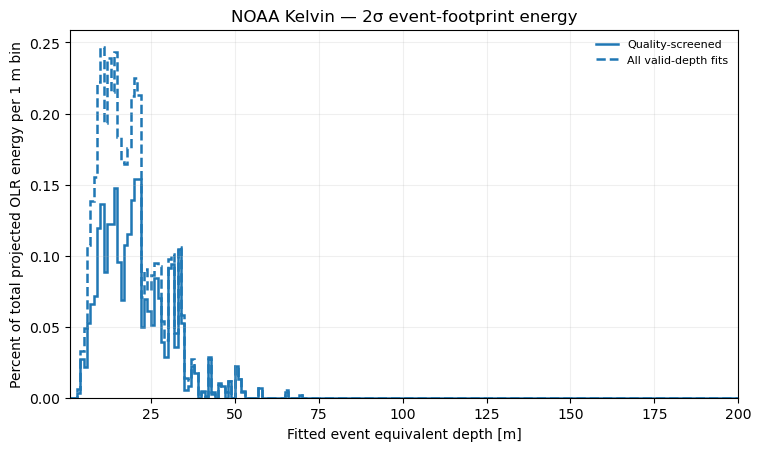

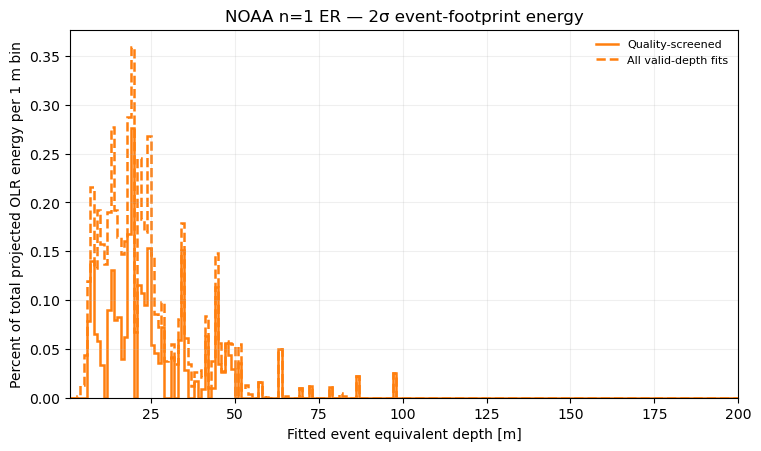

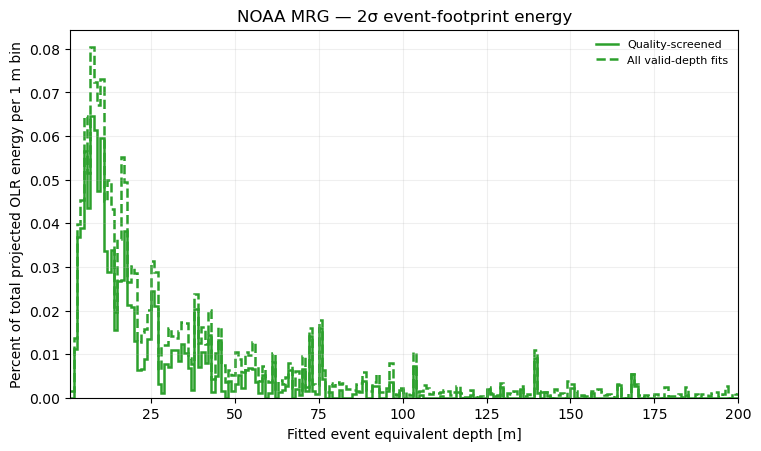

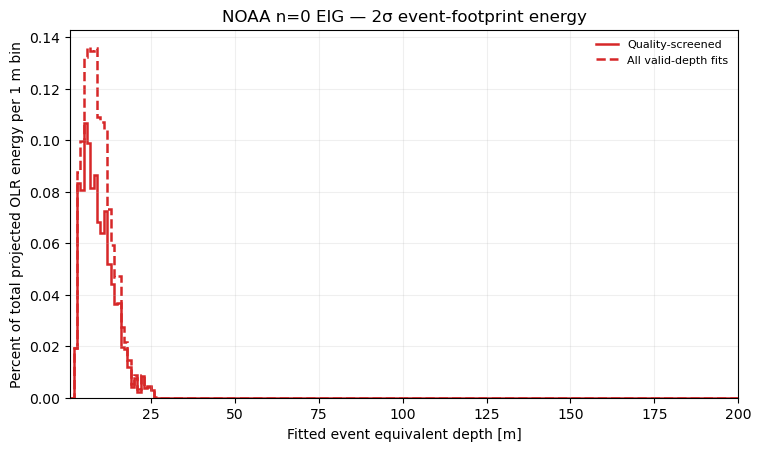

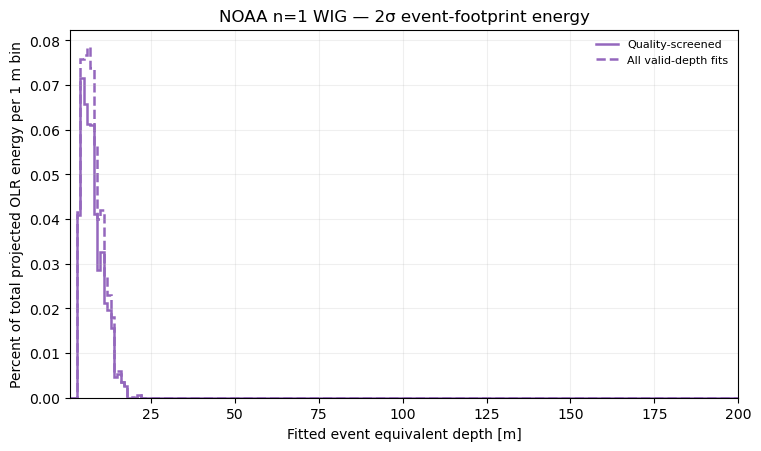

In [6]:
event_metrics = energy[["wave_type", "selection", "selected_events"]].copy()
for metric in ("support", "fitted"):
    all_bins = [f"{metric}_{i:03d}m" for i in range(1, 200)]
    band_bins = [f"{metric}_{i:03d}m" for i in range(12, 50)]
    event_metrics[f"{metric}_all_depths_pct"] = 100 * energy[f"selected_{metric}_energy"] / energy.denominator_energy
    event_metrics[f"{metric}_1_to_200_pct"] = 100 * energy[all_bins].sum(axis=1) / energy.denominator_energy
    event_metrics[f"{metric}_12_to_50_pct"] = 100 * energy[band_bins].sum(axis=1) / energy.denominator_energy
display(event_metrics.round(3))

for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.4), layout="constrained")
    columns = [f"support_{i:03d}m" for i in range(1, 200)]
    for selection, label in SELECTIONS.items():
        row = energy.loc[energy.wave_type.eq(wave) & energy.selection.eq(selection)].iloc[0]
        percent = 100 * row[columns].to_numpy(dtype=float) / row.denominator_energy
        ax.stairs(percent, EDGES_M, baseline=None, color=COLORS[wave],
                  linestyle=STYLES[selection], linewidth=1.8, label=label)
    ax.set(xlim=(1, 200), ylim=(0, None), xlabel="Fitted event equivalent depth [m]",
           ylabel="Percent of total projected OLR energy per 1 m bin",
           title=f"NOAA {LABELS[wave]} — 2σ event-footprint energy")
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=.2)
    plt.show()


## Energy explained by the event carrier fit

This diagnostic uses each component's local sum of squares and in-sample R².
It is not out-of-sample skill, statistical significance or a distinct causal
contribution by a physical normal mode.

The local explained sum of squares is the saved R² times
$\sum_{S_e}(q_w-\overline q_{S_e})^2$, with numerical R² bounded to [0, 1].
Its denominator is the same total projected energy as the footprint metric.

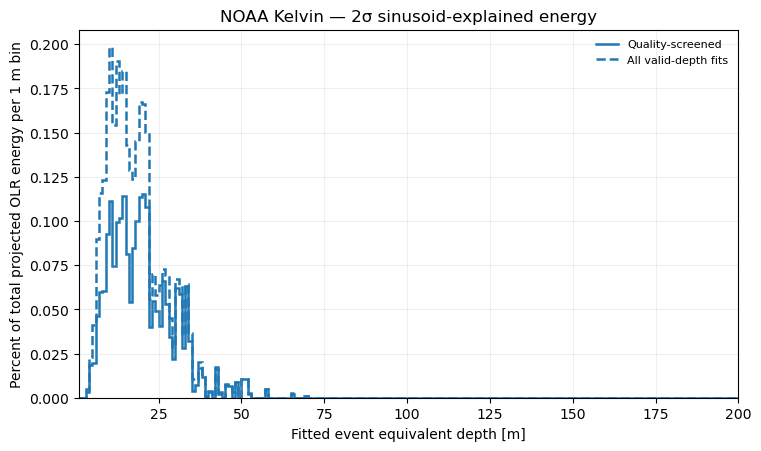

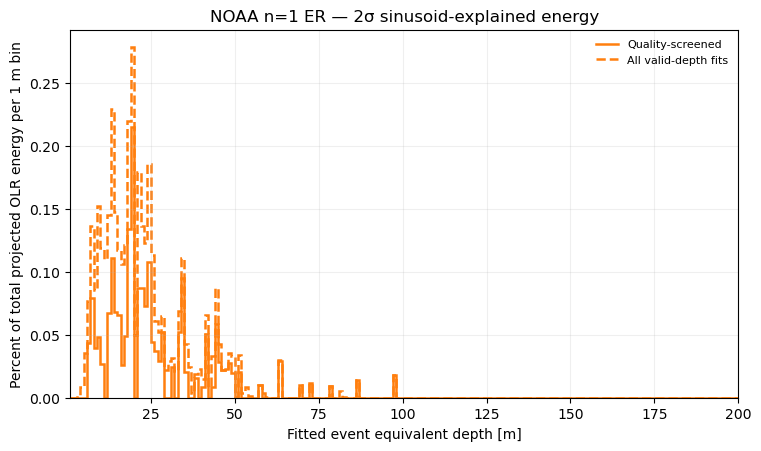

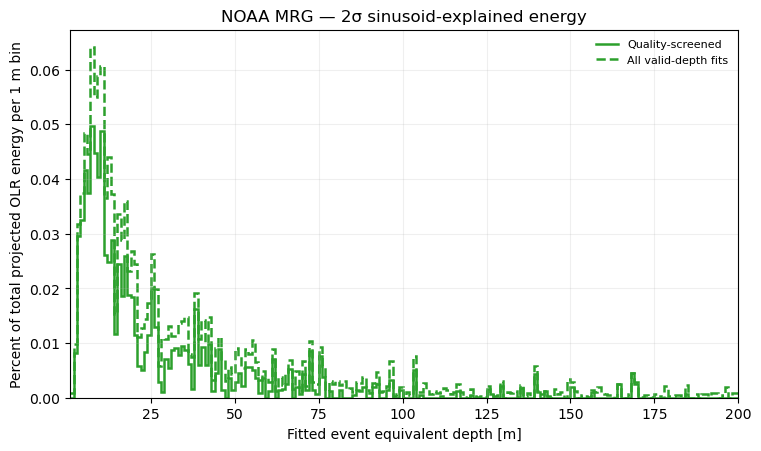

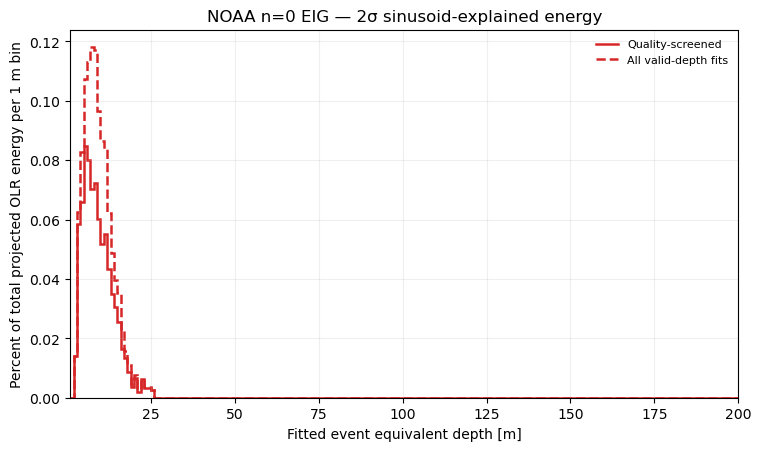

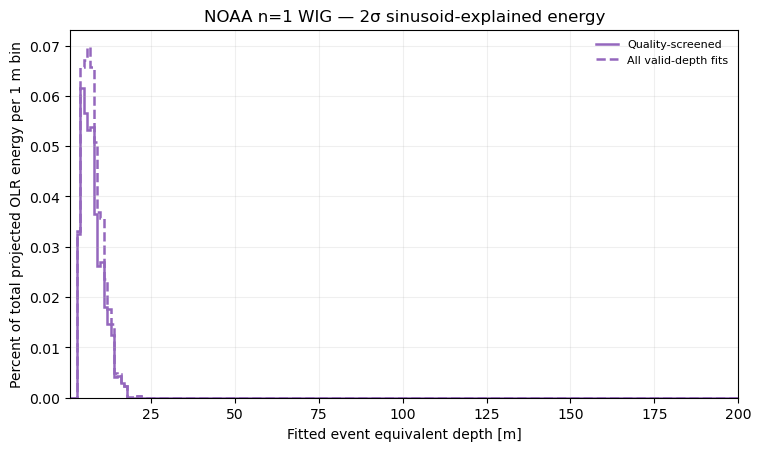

In [7]:
for wave in WAVES:
    fig, ax = plt.subplots(figsize=(7.5, 4.4), layout="constrained")
    columns = [f"fitted_{i:03d}m" for i in range(1, 200)]
    for selection, label in SELECTIONS.items():
        row = energy.loc[energy.wave_type.eq(wave) & energy.selection.eq(selection)].iloc[0]
        percent = 100 * row[columns].to_numpy(dtype=float) / row.denominator_energy
        ax.stairs(percent, EDGES_M, baseline=None, color=COLORS[wave],
                  linestyle=STYLES[selection], linewidth=1.8, label=label)
    ax.set(xlim=(1, 200), ylim=(0, None), xlabel="Fitted event equivalent depth [m]",
           ylabel="Percent of total projected OLR energy per 1 m bin",
           title=f"NOAA {LABELS[wave]} — 2σ sinusoid-explained energy")
    ax.legend(frameon=False, fontsize=8)
    ax.grid(alpha=.2)
    plt.show()


## Observed spectral power by apparent depth

This threshold-independent calculation is reused from the previous audit.
Fourier cells in each wave box receive a resting-branch depth. These are not
event-fit histograms and do not change when the envelope cutoff changes.
Only observed power is displayed.

,wave_type,full_box_pct,valid_depth_pct,one_to_200_m_pct,twelve_to_50_m_pct
0,Kelvin,9.193,9.193,8.868,4.258
1,MRG,4.045,3.675,3.083,0.960
2,n0EIG,2.884,2.884,2.879,0.971
3,n1ERW,11.523,11.523,10.437,4.264
4,n1WIG,1.214,1.214,1.214,0.294


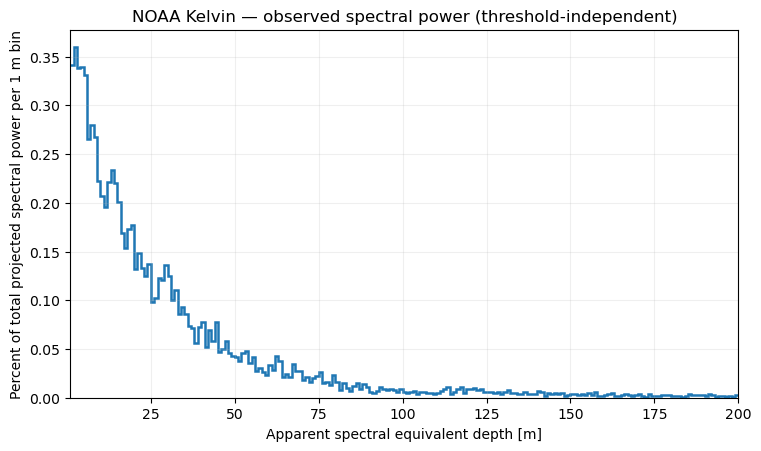

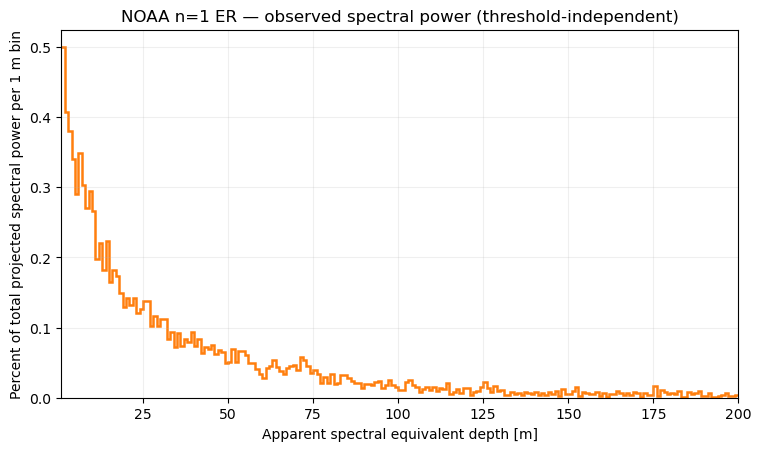

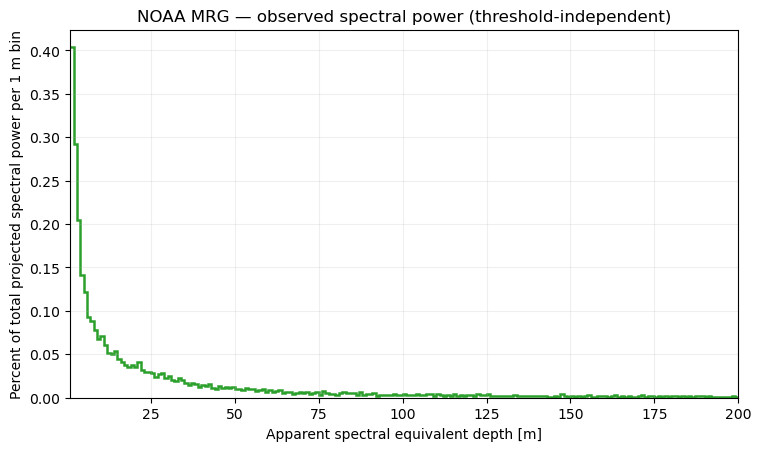

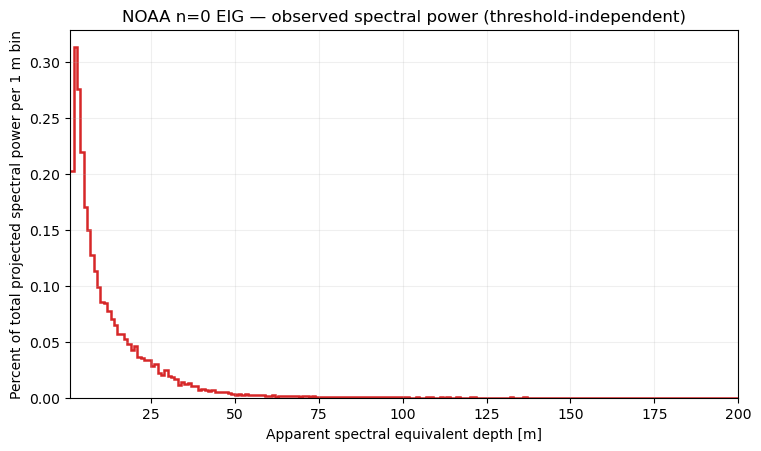

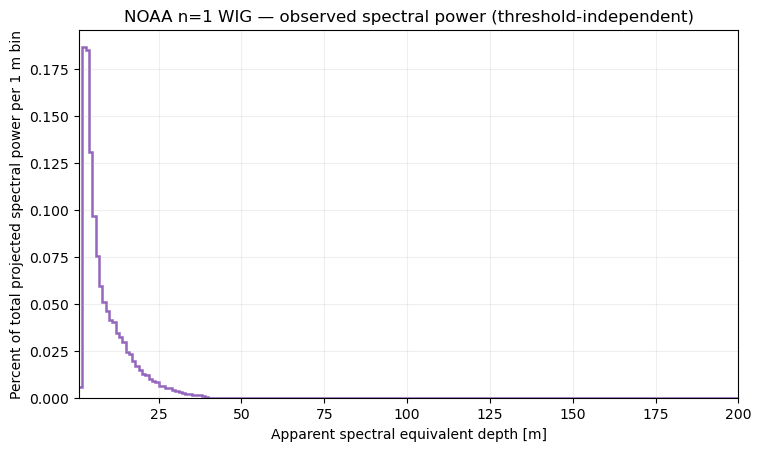

In [8]:
spectral_metrics = spectral[["wave_type"]].copy()
for column in ("full_box_power", "valid_depth_power", "one_to_200_m_power", "twelve_to_50_m_power"):
    spectral_metrics[column.replace("_power", "_pct")] = 100 * spectral[column] / spectral.denominator_power
display(spectral_metrics.round(3))

columns = [f"power_{i:03d}m" for i in range(1, 200)]
for wave in WAVES:
    row = spectral.loc[spectral.wave_type.eq(wave)].iloc[0]
    percent = 100 * row[columns].to_numpy(dtype=float) / row.denominator_power
    fig, ax = plt.subplots(figsize=(7.5, 4.4), layout="constrained")
    ax.stairs(percent, EDGES_M, baseline=None, color=COLORS[wave], linewidth=1.8)
    ax.set(xlim=(1, 200), ylim=(0, None), xlabel="Apparent spectral equivalent depth [m]",
           ylabel="Percent of total projected spectral power per 1 m bin",
           title=f"NOAA {LABELS[wave]} — observed spectral power (threshold-independent)")
    ax.grid(alpha=.2)
    plt.show()


## Interpretation and limits

At 2σ, NOAA's quality-screened median depths are 17.5 m for Kelvin, 23.2 m for ER, 19.0 m for MRG, 8.3 m for EIG and 7.3 m for WIG. MRG's all-valid median is 54.0 m, with 23.3% of valid depths above 200 m. The fit selection therefore remains important for comparing wave families.

The all-wave overview compares normalized event counts, while the event-energy
panels also retain amplitude and prevalence. Fit selection can materially change
inferred-depth distributions, especially the broad MRG tail. Higher in-sample R²
on a shorter active component alone does not establish more accurate depths.
Filter boxes, fit geometry, inversion and selection can themselves concentrate
fitted depths. The assigned dispersion branch and zero-background-wind assumption remain
consequential. All comparisons are descriptive, with one NOAA record.

No Gaussian comparison or new significance selection enters this remake.
Full catalog paths and run IDs are recorded in the threshold-comparison index;
all source event candidates and their flags remain preserved.

Daily sampling limits direction inference near the Nyquist frequency, especially
for WIG. These diagnostics do not recover subdaily propagation information.
